# Análise dos dados de  scRNA-seq:  
# Cell-cycle scoring
https://scanpy.readthedocs.io/en/stable/how-to/cell-cycle.html


> **AMBIENTES CONDA**
> - scRNA_NEW_signaling_py311

In [2]:
from sctools.degs import *
from sctools.functionalanalysis import *
from sctools.plots import PlotSignificanceHeatmap
from pathlib import Path
import matplotlib.pyplot as plt
import scanpy as sc
import pandas as pd
import numpy as np

# IMPORT

Only considering the two last: ['.neutrophils_annotated', '.h5ad'].
Only considering the two last: ['.neutrophils_annotated', '.h5ad'].


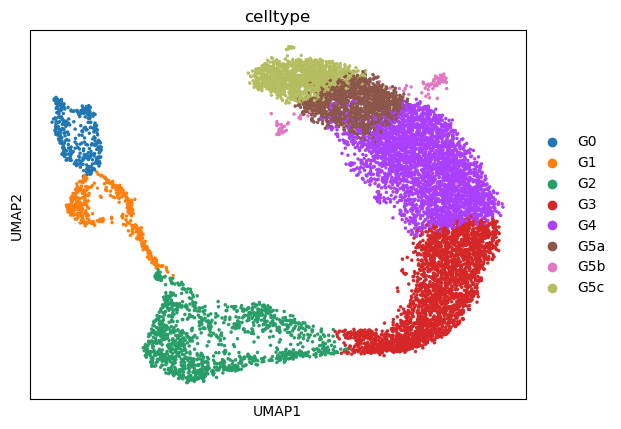

In [3]:
DATASET = "scNeuSheng"

celltype_col="celltype"
condition_col="condition"
sample_col="sample"
id_col="sample"
counts_layer="QC_filtered"
design_col="condition"
log_layer = counts_layer + "_log1p"

output_dir = Path(f"/media/tahila/DADOS/HD/2609_{DATASET}")
adata = sc.read(f"{output_dir}/06.scNeuSheng.neutrophils_annotated.h5ad")

sc.pl.umap(adata, color="celltype", frameon=True, size=25)

# Cell-cycle phases

The cell cycle consists of the stages a cell passes through to duplicate its DNA and divide:

| Phase | Main events |
|---|---|
| **G1** | The cell grows and prepares for DNA replication. |
| **S** | DNA is replicated. |
| **G2** | The cell prepares for division and checks replicated DNA. |
| **M** | Duplicated chromosomes are separated through mitosis, followed by cell division through cytokinesis. |

**G0** is a state outside the active cell cycle. Depending on cell identity and context, cells may remain quiescent, re-enter the cycle, or become terminally differentiated.

In Scanpy, cell-cycle scoring assigns cells to **S**, **G2M**, or **G1** based on the relative expression of S-phase and G2/M-associated genes. G2 and M are grouped because they share a transcriptional program.

**The G1 label does not distinguish true G1 cells from G0 or terminally differentiated cells.** It indicates that neither the S nor the G2M score is positive. These assignments estimate transcriptional state; they do not directly measure DNA content or the rate of cell division.

The Seurat gene lists contain only **S-phase** and **G2/M**-associated genes; there is no separate G1 signature. Scanpy calculates both scores and assigns cells to G1 when both are negative. Otherwise, the higher score determines the assignment to **S** or **G2M**. Therefore, the **G1** label reflects low relative expression of the **S** and **G2/M** programs rather than direct evidence of G1, and may also include quiescent (G0) or terminally differentiated cells.

# 1. Creating the Cell Cycle genes list for mouse

**Cell-cycle signatures**

S-phase and G2/M scores estimate the activity of DNA replication and mitotic progression programs in individual cells using the signatures described by Tirosh et al. (2016).

We used Seurat’s `cc.genes.updated.2019` object, exported from R to CSV, because it provides the signatures with gene symbols updated in 2019. The Scanpy tutorial supplies an earlier version containing some outdated symbols. This changes the source of the gene lists; scores are still calculated using Scanpy.

At the end, the file `/home/tahila/0.resources/cellcyclecell_cycle_genes_seurat_2019.csv` is exported representing the raw list provided.

References: [Tirosh et al., 2016](https://doi.org/10.1126/science.aad0501) · [Seurat gene lists](https://satijalab.org/seurat/reference/cc.genes.updated.2019)

In [16]:
%load_ext rpy2.ipython

In [19]:
%%R -o cc_table

# Download the official Seurat dataset
rda_url <- "https://raw.githubusercontent.com/satijalab/seurat/main/data/cc.genes.updated.2019.rda"
rda_file <- tempfile(fileext = ".rda")

download.file(rda_url, destfile = rda_file, mode = "wb")
load(rda_file)
unlink(rda_file)

# Convert the two gene lists to a table
cc <- cc.genes.updated.2019

cc_table <- data.frame(
    phase = c(
        rep("S", length(cc$s.genes)),
        rep("G2M", length(cc$g2m.genes))
    ),
    human_symbol = c(cc$s.genes, cc$g2m.genes)
)

# Export to CSV
out_dir <- "/home/tahila/0.resources/cellcycle"
dir.create(out_dir, recursive = TRUE, showWarnings = FALSE)

write.csv(
    cc_table,
    file.path(out_dir, "cell_cycle_genes_seurat_2019.csv"),
    row.names = FALSE
)

print(table(cc_table$phase))

R[write to console]: tentando a URL 'https://raw.githubusercontent.com/satijalab/seurat/main/data/cc.genes.updated.2019.rda'

R[write to console]: Content type 'application/octet-stream'
R[write to console]:  length 538 bytes

R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to console]: =
R[write to con


G2M   S 
 54  43 


In [20]:
display(cc_table)

,phase,human_symbol
1,S,MCM5
2,S,PCNA
3,S,TYMS
4,S,FEN1
5,S,MCM7
...,...,...
93,G2M,NEK2
94,G2M,G2E3
95,G2M,GAS2L3
96,G2M,CBX5


The list above is for humans, in case of alternate organism, a list of ortologues should be compiled. 

In [27]:
import decoupler as dc
# Copy the human column, then translate only the copy
cc_table["mouse_symbol"] = cc_table["human_symbol"]
cc_mouse = dc.op.translate(
    cc_table,
    columns=["mouse_symbol"],
    target_organism="mouse",
    min_evidence=3,
    one_to_many=1,
).drop_duplicates()

### Compute the number of human genes that were successfully translated to mouse genes, and the number of mouse genes per phase.
# Mouse gene list per phase (unique, in case two human genes map to the same mouse gene)
s_genes_mouse = cc_mouse.loc[
    cc_mouse["phase"].eq("S"), "mouse_symbol"
].unique().tolist()

g2m_genes_mouse = cc_mouse.loc[
    cc_mouse["phase"].eq("G2M"), "mouse_symbol"
].unique().tolist()

# Mouse genes kept / human genes in the original list
print(f"S: {len(s_genes_mouse)}/{cc_table['phase'].eq('S').sum()}")
print(f"G2M: {len(g2m_genes_mouse)}/{cc_table['phase'].eq('G2M').sum()}")

# Human genes lost in the translation (no ortholog, low evidence, or one-to-many)
unmapped = sorted(
    set(cc_table["human_symbol"]) - set(cc_mouse["human_symbol"])
)
print("Human genes requiring review:", unmapped)

cc_mouse

S: 43/43
G2M: 53/54
Human genes requiring review: ['CKS1B']


,phase,human_symbol,mouse_symbol
0,S,MCM5,Mcm5
1,S,PCNA,Pcna
2,S,TYMS,Tyms
3,S,FEN1,Fen1
4,S,MCM7,Mcm7
...,...,...,...
91,G2M,NEK2,Nek2
92,G2M,G2E3,G2e3
93,G2M,GAS2L3,Gas2l3
94,G2M,CBX5,Cbx5


In [26]:
# Manually curated orthologue: human CKS1B -> mouse Cks1b (NCBI Gene 54124)
g2m_genes_mouse = list(dict.fromkeys(g2m_genes_mouse + ["Cks1b"]))

print("Cks1b present in dataset:", "Cks1b" in adata.var_names)

Cks1b present in dataset: True


In [28]:
# Save the translated table to CSV, over the same directory as the original
cc_mouse.to_csv("/home/tahila/0.resources/cellcycle/cell_cycle_genes_seurat_2019_human_mouse.csv", index=False)

# 2. Applying the Cell Cycle score using the obtained list

In [ ]:
# Load the human-mouse cell cycle table saved in section 1
cc_mouse = pd.read_csv("/home/tahila/0.resources/cellcycle/cell_cycle_genes_seurat_2019_human_mouse.csv")

# Keep only genes present in the dataset (score_genes_cell_cycle needs them in adata.var_names)
s_genes = [g for g in s_genes_mouse if g in adata.var_names]
g2m_genes = [g for g in g2m_genes_mouse if g in adata.var_names]

print(f"S: {len(s_genes)}/{len(s_genes_mouse)} in dataset")
print(f"G2M: {len(g2m_genes)}/{len(g2m_genes_mouse)} in dataset")
print("Not in dataset:", sorted(set(s_genes_mouse + g2m_genes_mouse) - set(adata.var_names)))

S: 43/43 in dataset
G2M: 53/53 in dataset
Not in dataset: []


Use the filtered and normalized layer, the layer where the below filters and transformations were applied:

```python
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
```

In [5]:
adata.X = adata.layers[log_layer].copy()

We here perform cell cycle scoring. The function is actually a wrapper to `scanpy.tl.score_genes()`, which is launched twice, to score separately S and G2M phases.  
Both `scanpy.tl.score_genes()` and `scanpy.tl.score_genes_cell_cycle()` are a port from Seurat and are supposed to work in a very similar way.  

To score a gene list, the algorithm calculates the difference of mean expression of the given list and the mean expression of reference genes.  

To build the reference, the function randomly chooses a bunch of genes matching the distribution of the expression of the given list.  

Cell cycle scoring adds three slots in data: 
- a score for S phase, 
- a score for G2M phase 
- the predicted cell cycle phase.

In [6]:
sc.tl.score_genes_cell_cycle(adata, s_genes=s_genes, g2m_genes=g2m_genes)

adata.obs[['phase', 'S_score', 'G2M_score']].head(5)

,phase,S_score,G2M_score
AAACCCAAGAAGCCTG-1-49,S,0.260724,-0.031205
AAACCCAAGTCAATCC-1-49,G1,-0.020069,-0.007017
AAACCCAAGTCATGCT-1-49,G2M,-0.033647,0.152116
AAACCCAGTGAGTCAG-1-49,G1,-0.032571,-0.020914
AAACCCAGTTCCCACT-1-49,G1,-0.068409,-0.149400


Here comes another difference from Seurat. The R package stores raw data, scaled data and variable genes information in separate slots, 

Scanpy instead keeps only one snapshot of the data.

This implies that PCA is always calculated on the entire dataset.  
In order to calculate PCA reduction using only a subset of genes (like cell_cycle_genes), a trick should be used.  

Basically we create a dummy object to store information of PCA projection, which is then reincorporated into original dataset.

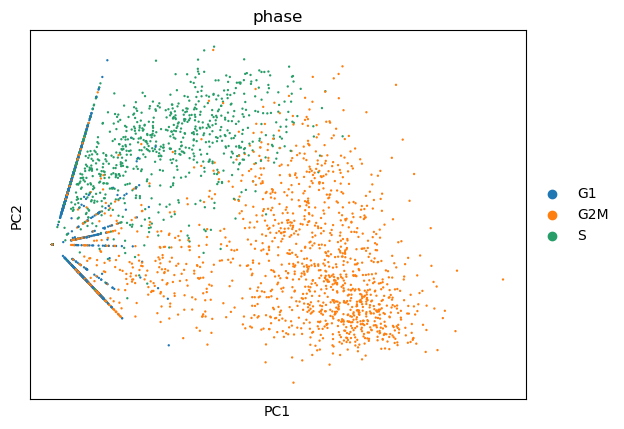

In [7]:
cell_cycle_genes = s_genes + g2m_genes

adata_cc_genes = adata[:, cell_cycle_genes].copy()
sc.tl.pca(adata_cc_genes)
sc.pl.pca(adata_cc_genes, color="phase")

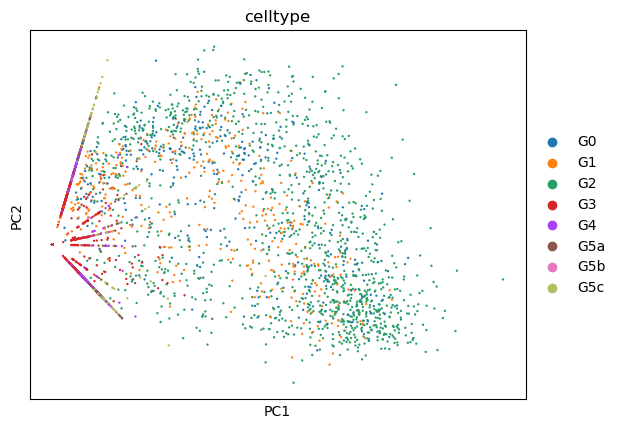

In [8]:
sc.pl.pca(adata_cc_genes, color="celltype")

As in the original vignette, cells can be easily separated by their cell cycle status when cell cycle genes are used. Now we can regress out both S score and G2M score.

### Regressing out covariates with Scanpy

`sc.pp.regress_out()` fits a linear regression model for each gene using covariates stored in `adata.obs`. It replaces the expression values with the residuals: the variation remaining after accounting for those covariates.

For example, `sc.pp.regress_out(adata, keys=["S_score", "G2M_score"])` reduces expression variation linearly associated with cell-cycle scores across all analyzed genes, rather than removing only cell-cycle genes.

This optional step can help prevent cell-cycle differences from dominating PCA and clustering. However, it can also remove meaningful biological variation when proliferation is associated with cell identity or experimental condition. Scanpy explicitly warns about potential overcorrection.

By default, the function modifies `adata.X` and may produce negative values. Preserve the original counts and normalized expression separately. Use the residual matrix for dimensionality reduction when appropriate, rather than as input to count-based differential expression methods.

Regression does not update an existing UMAP. PCA, the neighbor graph, and UMAP must be recalculated to visualize its effect.

**For this analysis:** if proliferation is an outcome of interest, retain the original expression and cell-cycle scores and assess whether regression is justified.

Reference: [Scanpy documentation](https://scanpy.readthedocs.io/en/stable/generated/scanpy.pp.regress_out.html)

### What does cell-cycle regression do?

Cell-cycle regression removes the component of each gene’s expression that is linearly associated with `S_score` and `G2M_score`.

For each gene, it fits a linear model using these scores, predicts expression, and subtracts that prediction from the observed values. The resulting **residuals** represent expression above or below what the model predicts.

This changes expression values; it does not remove genes or cells. Genes outside the cell-cycle signature can also be affected if their expression is associated with the scores.

The model cannot distinguish unwanted variation from meaningful biology. For example, expression differences linked to proliferation in the early neutrophil stages (G0 to G2) may also be reduced.

After regression, the analysis explores the differences that remain after accounting for their linear association with cell-cycle activity. Original expression values and scores should be preserved for studying proliferation.

In [9]:
sc.pp.regress_out(adata, ["S_score", "G2M_score"])

Finally, we project the dataset again using the cell-cycle genes. After regression, the separation by phase is smaller, but it is not fully removed (see the interpretation below).

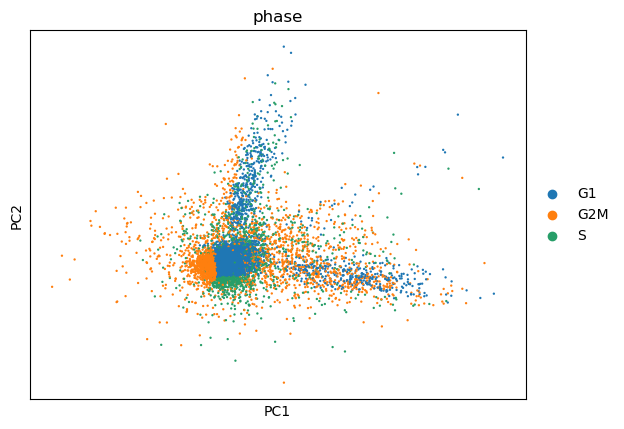

In [10]:
adata_cc_genes = adata[:, cell_cycle_genes].copy()
sc.tl.pca(adata_cc_genes)
sc.pl.pca(adata_cc_genes, color="phase")

### Interpreting the PCA before and after cell-cycle regression

PCA summarizes differences in gene expression between cells. Each point is a cell. Cells close to each other have similar expression of the genes used. Here the PCA uses only the cell-cycle genes, so PC1 and PC2 describe variation inside the cell-cycle signature, not the overall structure of the dataset.

**Note on names:** the cell types G0 to G5c are neutrophil maturation stages (Xie et al., 2020). They are not cell-cycle phases. The cell-cycle phase is in the `phase` column (G1, S, G2M).

**Before regression:** cells separate by predicted phase. S cells occupy the upper region and G2M cells extend to the right and lower region. G1 cells are compressed at the left edge, many of them along straight lines. These lines are cells that express very few cell-cycle genes, so they get almost the same coordinates. Coloring by cell type shows that the S and G2M region is mostly G2 cells, with some G1 and G0 cells. G3, G4 and G5a to G5c cells stay at the left edge, together with the G1 phase. This agrees with Xie et al. (2020): proliferation is concentrated in G0 to G2, and G3 to G5 are post-mitotic.

**After regression:** the phases no longer separate along PC1 and PC2 as before, but they still do not fully overlap. G2M cells form a dense group on the left side of the center. Regression removes only the linear association with the scores, so part of the variation linked to the cell cycle can remain. The colors are the original phase assignments, because regression does not update `phase`.

**What this comparison tells us:** regression reduced the separation by phase. It does not show that the corrected data is biologically better. In this dataset, proliferation is part of the identity of the early stages (G0 to G2). Regression can weaken the differences between proliferating precursors and post-mitotic neutrophils, which are part of the biology we want to study.

**Limitation:** the PCA is recalculated after regression, so PC1 and PC2 do not represent the same expression patterns before and after.

For studying proliferation, keep the scores calculated before regression. To decide if regression helps to identify cell types, compare the representations with cell-type markers and sample labels.

# Cell-cycle activity across cell types

We visualize predicted cell-cycle phases (`phase`) and S-phase scores (`S_score`) on the UMAP to explore how cell-cycle activity is distributed across annotated cell types. Phase labels summarize the assignments, while the continuous S-phase score highlights variation in the DNA replication program within and between populations.

These plots help identify populations enriched in cycling cells and heterogeneity within each cell type. They provide an exploratory view rather than a direct measurement of proliferation rate. G2/M scores should also be examined, since low S-phase activity alone does not imply that a cell is noncycling.

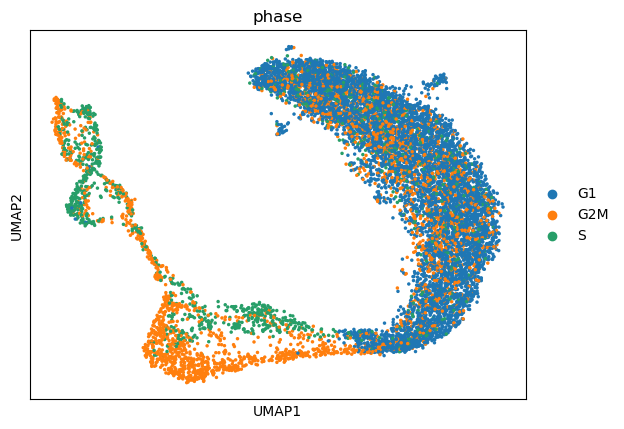

In [11]:
sc.pl.umap(adata, color="phase", frameon=True, size=25)

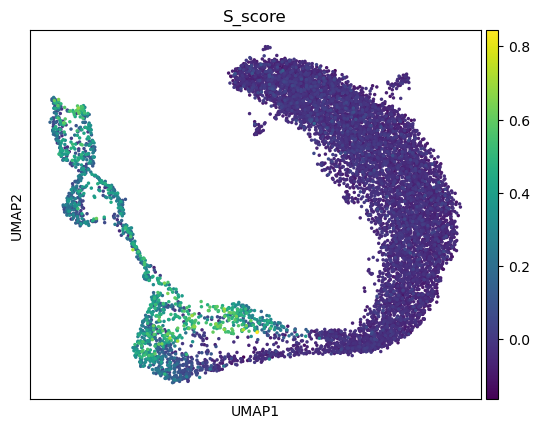

In [12]:
sc.pl.umap(adata, color="S_score", frameon=True, size=25)

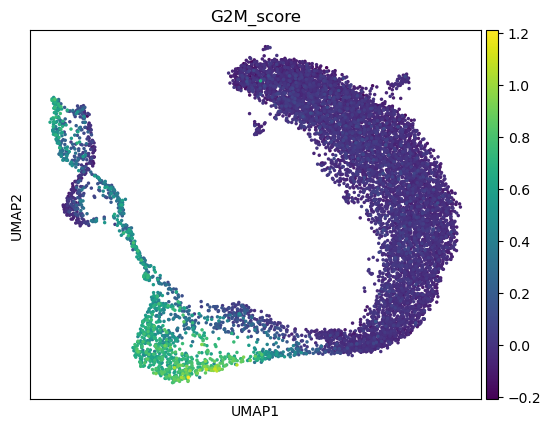

In [13]:
sc.pl.umap(adata, color="G2M_score", frameon=True, size=25)

# Function  to `sctools`

In [ ]:
def ScoreCellCycle(
    adata: AnnData,
    genes_csv: str | Path,
    gene_col: str = "mouse_symbol",
    phase_col: str = "phase",
    layer: str = "QC_filtered_log1p",
    plot_umap: bool = True,
) -> AnnData:
    """
    Score S and G2/M phases per cell and assign a cell-cycle phase.

    Reads the S and G2/M genes from a CSV table, keeps the genes present in
    `adata.var_names` (case-insensitive match), then runs
    `sc.tl.score_genes_cell_cycle` on `layer`.

    Parameters
    ----------
    adata
        AnnData object. Writes `S_score`, `G2M_score` and `phase` to
        `adata.obs`.
    genes_csv
        CSV with one row per gene, e.g.
        `cell_cycle_genes_seurat_2019_human_mouse.csv`.
    gene_col
        Column with the gene symbols, in the same organism as `adata`.
    phase_col
        Column with the phase of each gene. Values must be "S" and "G2M".
    layer
        Layer with log-normalized expression (not scaled).
    plot_umap
        If True, plot `phase`, `S_score` and `G2M_score` on the UMAP.

    Returns
    -------
    AnnData
        Same object (modified in place). Parameters are recorded in
        `adata.uns["annotation_params"]["cell_cycle"]`.

    Notes
    -----
    Genes not found in `adata.var_names` are dropped and listed in a
    warning.

    Domain note: `score_genes` compares each gene set with control genes of
    similar mean expression, so `layer` must be log-normalized, not scaled
    (scaling removes the mean used to pick the controls).

    Domain note: phase "G1" also covers G0 and post-mitotic cells, so
    mature cells (e.g. neutrophils, mature enterocytes) are expected to be
    almost all "G1". The score is evidence for annotation. Do not regress
    it out at this step.

    Domain note: Seurat's `cc.genes.updated.2019` (made with
    `UpdateSymbolList`) replaces MCM2, RPA2 and BRIP1 by MCM7, POLR1B and
    MRPL36. MCM2, RPA2 and BRIP1 are current HGNC symbols, so these three
    changes come from symbol clashes, not from biology. Check the table if
    it was built from that list.
    """
    _CheckLayer(adata, layer)
    table = pd.read_csv(genes_csv)
    for col in (gene_col, phase_col):
        if col not in table.columns:
            raise KeyError(f"Column '{col}' not found in {genes_csv}. Available: {list(table.columns)}")
    phases = set(table[phase_col].astype(str))
    if phases != {"S", "G2M"}:
        raise ValueError(f"Column '{phase_col}' must have only 'S' and 'G2M'. Found: {sorted(phases)}")

    s_genes = table.loc[table[phase_col].eq("S"), gene_col].dropna().tolist()
    g2m_genes = table.loc[table[phase_col].eq("G2M"), gene_col].dropna().tolist()

    # Keep only genes present in the dataset (spelled as in adata.var_names, no duplicates)
    var_map = _VarMap(adata.var_names)
    s_found = _MatchGenes(s_genes, var_map)
    g2m_found = _MatchGenes(g2m_genes, var_map)
    logger.info(
        "S: %d/%d genes in dataset. G2M: %d/%d genes in dataset.",
        len(s_found), len(set(s_genes)), len(g2m_found), len(set(g2m_genes)),
    )
    missing = sorted({str(g) for g in [*s_genes, *g2m_genes] if str(g).upper() not in var_map})
    if missing:
        logger.warning("%d cell-cycle genes not in adata.var_names, dropped: %s", len(missing), missing)
    if not s_found or not g2m_found:
        raise ValueError(
            f"No S or G2M gene found in adata.var_names (S: {len(s_found)}, G2M: {len(g2m_found)}). "
            f"Check that `gene_col` ('{gene_col}') is in the same organism as adata."
        )

    sc.tl.score_genes_cell_cycle(adata, s_genes=s_found, g2m_genes=g2m_found, layer=layer, use_raw=False)

    adata.uns.setdefault("annotation_params", {})["cell_cycle"] = {
        "layer": layer,
        "genes_csv": str(genes_csv),
        "gene_col": gene_col,
        "n_s_genes": len(s_found),
        "n_g2m_genes": len(g2m_found),
    }

    if plot_umap:
        sc.pl.umap(adata, color=["phase", "S_score", "G2M_score"], frameon=True, size=25)

    return adata

INFO:sctools.annotation:S: 43/43 genes in dataset. G2M: 53/53 genes in dataset.


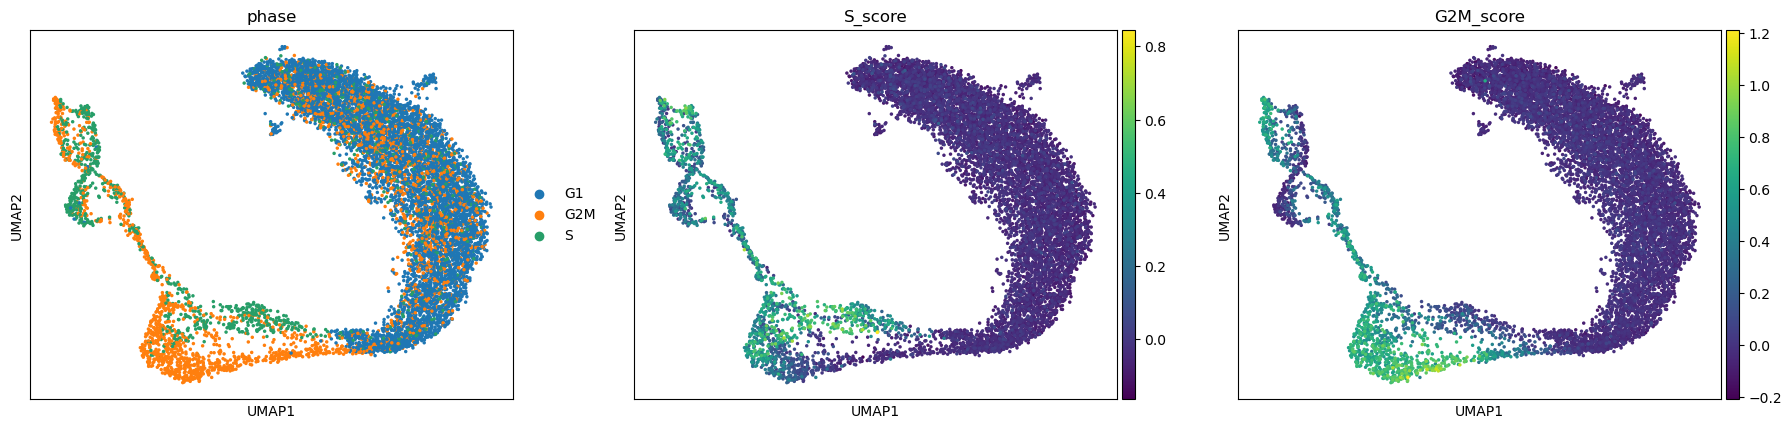

In [15]:
from sctools.annotation import ScoreCellCycle

adata = ScoreCellCycle(
    adata,
    genes_csv="/home/tahila/0.resources/cellcycle/cell_cycle_genes_seurat_2019_human_mouse.csv",
    layer="QC_filtered_log1p",
)


---

**Note on AI tools:** Claude Code (Anthropic) and ChatGPT (OpenAI) were used to help write the code and the text of this notebook. All code, results and interpretations were reviewed by the author.